Layer dalam GeoPackage: ['change_feature']


C:\Users\konil\anaconda3\envs\geo\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column date_before, 2023-08-12T00:00:00.0Z, successfully parsed
  return ogr_read(


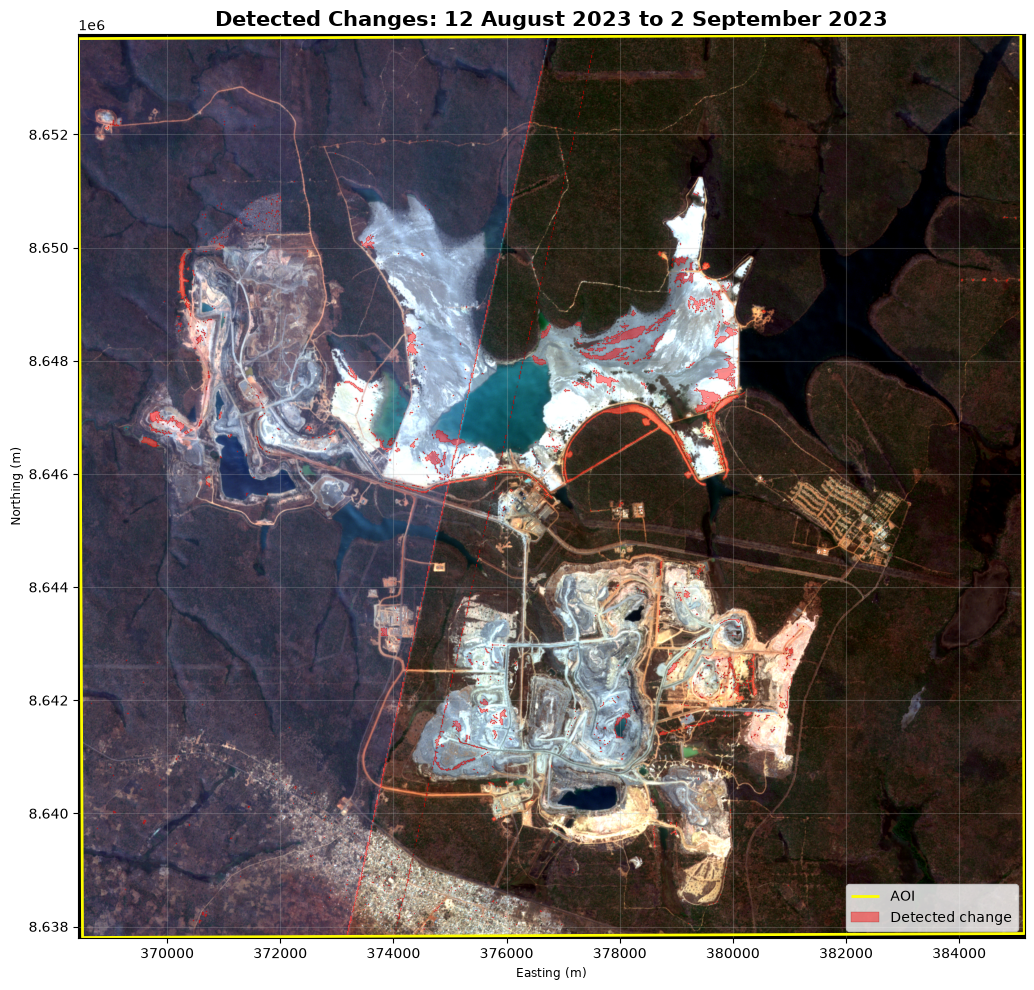

Visualisasi tersimpan di:
C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\data\processed\change_visualization.png


In [1]:
from pathlib import Path

import fiona
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.plot import plotting_extent

# Lokasi folder tugas
ROOT = Path(r"C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment")
DATA = ROOT / "data"

# Input
aoi_path = ROOT / "aoi.geojson"
gpkg_path = DATA / "processed.gpkg"

b02_path = DATA / "sentinel2_20230902" / "B02.tif"
b03_path = DATA / "sentinel2_20230902" / "B03.tif"
b04_path = DATA / "sentinel2_20230902" / "B04.tif"

# Output
output_dir = DATA / "processed"
output_dir.mkdir(exist_ok=True)
output_png = output_dir / "change_visualization.png"

# Cek dan baca layer polygon dari GeoPackage
layers = fiona.listlayers(gpkg_path)
print("Layer dalam GeoPackage:", layers)

changes = gpd.read_file(gpkg_path, layer=layers[0])
aoi = gpd.read_file(aoi_path)

# Baca band Sentinel-2: B04=merah, B03=hijau, B02=biru
with rasterio.open(b04_path) as src:
    red = src.read(1).astype("float32")
    raster_crs = src.crs
    extent = plotting_extent(src)

with rasterio.open(b03_path) as src:
    green = src.read(1).astype("float32")

with rasterio.open(b02_path) as src:
    blue = src.read(1).astype("float32")

# Sesuaikan CRS polygon dengan raster
if aoi.crs != raster_crs:
    aoi = aoi.to_crs(raster_crs)

if changes.crs != raster_crs:
    changes = changes.to_crs(raster_crs)

# Contrast stretch 2--98 persen per band agar citra lebih jelas
def stretch(band):
    lower, upper = np.percentile(band[band > 0], (2, 98))
    return np.clip((band - lower) / (upper - lower), 0, 1)

rgb = np.dstack([stretch(red), stretch(green), stretch(blue)])

# Buat peta
fig, ax = plt.subplots(figsize=(12, 10))

ax.imshow(rgb, extent=extent)

# AOI: batas kuning
aoi.boundary.plot(
    ax=ax,
    color="yellow",
    linewidth=2,
    label="AOI"
)

# Polygon perubahan: merah transparan
changes.plot(
    ax=ax,
    facecolor="red",
    edgecolor="darkred",
    linewidth=0.35,
    alpha=0.45,
    label="Detected change"
)

ax.set_title(
    "Detected Changes: 12 August 2023 to 2 September 2023",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(output_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"Visualisasi tersimpan di:\n{output_png}")

In [2]:
from pathlib import Path

report = """# Sentinel-2 Change Analysis Report

## Method

This analysis compares Sentinel-2 imagery acquired on 12 August 2023 and 2 September 2023 over an open-pit mining site in Zambia.

Bands B02 (blue), B03 (green), and B04 (red) were loaded for both dates. The raster datasets were checked for consistent coordinate reference system, geotransform, dimensions, and 10 m spatial resolution. The three bands were stacked into multi-band images for each acquisition date.

Change intensity was calculated using the squared Euclidean spectral distance:

D² = (B02_after - B02_before)² + (B03_after - B03_before)² + (B04_after - B04_before)²

This method was selected because it combines change information from all available visible bands into one change-intensity raster. A threshold of approximately 1,083,687 was used to create a binary change map. Pixels above the threshold were classified as detected change.

Detected-change pixels were converted to polygons. For each polygon, the before date, after date, area in square metres, and mean change-intensity score were stored in a GeoPackage database.

## Results

The analysis identified 1,833 detected-change polygons with a combined area of approximately 3,052,600 m² (305.26 hectares). Polygon areas range from approximately 100 m² to 356,300 m².

Detected changes are concentrated around the open-pit mining complex, especially near exposed ground, mining infrastructure, haul roads, and disturbed land in the central and northern parts of the AOI. Smaller change polygons are distributed throughout the surrounding landscape.

The confidence field represents the mean spectral change-intensity score for each polygon. Higher values indicate stronger spectral differences between the two dates.

## Interpretation

The detected patterns may represent operational changes at the mining site, such as excavation, earth movement, expansion of exposed soil, road activity, or changes in water and sediment conditions.

Some detected changes may also be caused by seasonal vegetation variation, illumination differences, atmospheric conditions, cloud or haze, and sensor noise. Bright cloud-affected areas should therefore be interpreted cautiously, because they can create false-positive change signals.

The result is suitable as a screening product for identifying candidate change areas. Validation with cloud masks, additional dates, higher-resolution imagery, or ground information would improve confidence in the interpretation.
"""

report_path = Path(
    r"C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\report.md"
)

report_path.write_text(report, encoding="utf-8")
print(f"Report created: {report_path}")

Report created: C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\report.md


In [3]:
from pathlib import Path

readme = """# Sentinel-2 Change Analysis

## Overview

This project analyses land-surface changes between Sentinel-2 imagery acquired on 12 August 2023 and 2 September 2023 over an open-pit mining site in Zambia.

## Inputs

- `aoi.geojson`: Area of interest boundary
- `data/sentinel2_20230812/`: Sentinel-2 Bands B02, B03, and B04 for the first date
- `data/sentinel2_20230902/`: Sentinel-2 Bands B02, B03, and B04 for the second date

## Method

Bands B02, B03, and B04 were combined for each date. Change intensity was calculated using squared Euclidean spectral distance across the three bands. A threshold was applied to create a binary change raster. Detected-change pixels were converted into polygon features.

## Outputs

- `data/processed/esd/change_map.tif`: Change-intensity raster
- `data/processed/esd/change_binary.tif`: Binary change raster
- `data/processed/esd/processed.gpkg`: GeoPackage database containing `change_feature`
- `data/data/processed/esd/change_visualization.png`: Map visualisation of detected changes
- `report.md`: Interpretation of methods and results

## Database fields

The `change_feature` table contains:

- `date_before`
- `date_after`
- `area_m2`
- `confidence`
- polygon geometry

## Visualisation

Open `change_visualization.ipynb` in Jupyter Notebook and run all cells to generate the change visualisation.
"""

readme_path = Path(
    r"C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\README.md"
)

readme_path.write_text(readme, encoding="utf-8")
print(f"README created: {readme_path}")

README created: C:\Users\konil\Downloads\Technical Assignment_DS\Technical Assignment\README.md
